# Embedding, vector store and search (KAN-97)
Gözde Nur Özdemir · ELIZA · Sprint 2

**What the course asks for in Sprint 2:** *"the most basic vector database and retrieval over your documents"*, with the parameters in `config/rag.yaml`, and by 11/11: *"retrieval returns passages for a handful of test questions"*.

**What this notebook does:** it turns our 105 chunks into vectors, stores them in a vector database, and returns the 5 best chunks for a question. It first checks the embedding model chosen in Sprint 1 on my questions. The other settings (words BM25 ignores, search mode) are **chosen and tested in `src/evaluation.ipynb`** and written in `config/rag.yaml`; this notebook only builds the system with them.

| Step | What | Setting from `config/rag.yaml` |
|---|---|---|
| 1 | Load the settings and the chunks | |
| 2 | Was the Sprint 1 embedding model a good choice? Checked with Recall@5, MRR and Precision@5 | `embedding.model`, D10 |
| 3 | Turn the chunks into vectors (embedding) | `embedding.model` |
| 4 | Store the vectors in Chroma | `vector_store` |
| 5 | Keyword index (BM25) | `bm25.jury_words` |
| 6 | Search: dense (E1) and hybrid (E2) | `retrieval` |
| 7 | My questions, one by one (11/11 check) | |
| 8 | A picture of the chunks | |

**Questions used:** only my questions on Annex III 3(b): B-01 to B-06 for the scores, and the safety questions B-S1 to B-S3 in step 7.

## Summary
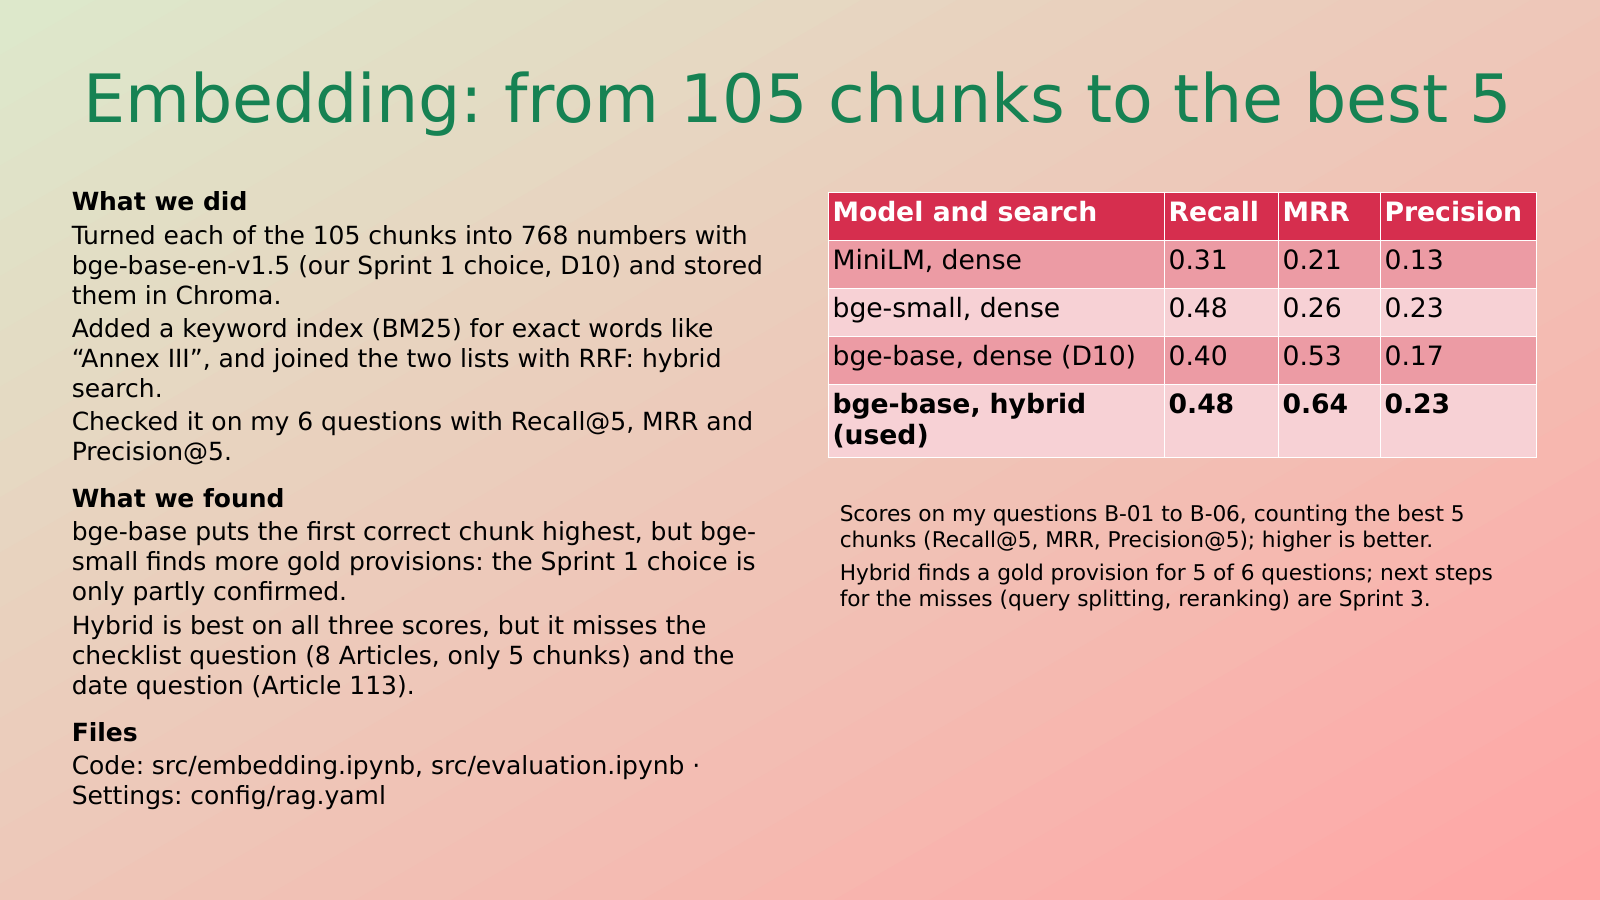

**Install once, in the terminal** (not in the notebook), in the same Python environment as Jupyter:
```
pip install sentence-transformers chromadb rank_bm25 pandas pyyaml requests scikit-learn umap-learn matplotlib
```

## 1. Load the settings and the chunks
The chunks come from `src/chunking.ipynb`. The notebook works in the repository (opened from `src/`) or from the folder `ELIZA` in your home folder, which holds the notebooks, `rag.yaml`, `chunks.jsonl` and `eval-set-v1.csv`.

In [56]:
import csv, json, os, re
from collections import Counter
import numpy as np, pandas as pd, requests, yaml
pd.set_option("display.max_colwidth", None)
np.random.seed(42)

HOME = os.path.expanduser("~")
try:
    here = os.getcwd()
except OSError:                                     # the folder this notebook was started in was deleted or is blocked
    os.chdir(HOME)
    here = HOME

def readable(folder):
    """True if rag.yaml in this folder can be opened (macOS can block Downloads, Desktop and Documents)."""
    try:
        open(os.path.join(folder, "rag.yaml")).close()
        return True
    except OSError:
        return False

IN_REPO = os.path.exists("../config/rag.yaml")      # opened from src/ in the repository
places = [here] + [os.path.join(HOME, p, "ELIZA") for p in ["", "Downloads", "Desktop", "Documents"]]
FOLDER = next((f for f in places if readable(f)), None)
assert IN_REPO or FOLDER, f"rag.yaml not found or blocked. Move the ELIZA folder into your home folder: {HOME}"
print("Files read from:", "the repository" if IN_REPO else "the ELIZA folder")      # no personal path in the output
P = lambda path: path if IN_REPO else os.path.join(FOLDER, os.path.basename(path))
CONFIG = yaml.safe_load(open(P("../config/rag.yaml")))
chunks = [json.loads(line) for line in open(P("../data/chunks.jsonl"), encoding="utf-8")]
questions = {r["id"]: r for r in csv.DictReader(open(P("../docs/eval/eval-set-v1.csv"), encoding="utf-8-sig"))}
ref_of = {c["chunk_id"]: c["ref"] for c in chunks}
words = lambda text: re.findall(r"[a-z0-9]+", text.lower())
print(len(chunks), "chunks,", len(questions), "questions")
CONFIG

Files read from: the ELIZA folder
105 chunks, 26 questions


{'chunking': {'strategy': 'structure',
  'source_file': 'CELEX_02024R1689-20260727_EN.html',
  'version_date': '27/07/2026',
  'celex': '02024R1689-20260727',
  'max_chars': 1500},
 'embedding': {'model': 'BAAI/bge-base-en-v1.5',
  'candidates': ['sentence-transformers/all-MiniLM-L6-v2',
   'BAAI/bge-small-en-v1.5',
   'BAAI/bge-base-en-v1.5'],
  'query_instruction': 'Represent this sentence for searching relevant passages: '},
 'vector_store': {'path': '../data/vector-store'},
 'bm25': {'remove': 'jury',
  'jury_words': ['a',
   'and',
   'for',
   'in',
   'of',
   'shall',
   'that',
   'the',
   'this',
   'to',
   'with']},
 'judge': {'jury': ['qwen3:4b', 'phi4-mini', 'gemma3:4b'],
  'url': 'http://localhost:11434/api/chat'},
 'retrieval': {'mode': 'hybrid', 'top_k': 5, 'candidates': 20, 'rrf_k': 60}}

## 2. Was the Sprint 1 embedding model a good choice?
An embedding model turns a text into a list of numbers (a vector); texts with a similar meaning get similar numbers, even when they share no words. A question like *"our AI grades exams"* can then find Annex III 3(b) (*"evaluate learning outcomes"*).

In Sprint 1 the design document (decision D10) compared three open models that run on a CPU and chose **`bge-base-en-v1.5`**, from published results, and said it would be checked on our questions. We check it here: each model embeds the 105 chunks and searches my questions **B-01 to B-06**. Scores, as in the instructor's slides (*"compute Recall@k / MRR on gold IDs"*):
- **Recall@5:** share of the gold provisions in the top 5 (4 gold provisions, 2 found = 0.5)
- **MRR:** how high the first correct chunk is (1.0 = always first, 0.5 = second)
- **Precision@5:** share of the top 5 that are gold provisions (unrelated chunks lower it)

| Model | Numbers per text | In D10 |
|---|---|---|
| `sentence-transformers/all-MiniLM-L6-v2` | 384 | very small, weaker on retrieval |
| `BAAI/bge-small-en-v1.5` | 384 | small, proposed in Spike 01 |
| `BAAI/bge-base-en-v1.5` | 768 | **chosen in Sprint 1**: stronger on retrieval, MIT licence |

**Rule:** the Sprint 1 choice stays unless another model is better on **both** Recall@5 and MRR.

In [58]:
dev = [questions[q] for q in ["B-01", "B-02", "B-03", "B-04", "B-05", "B-06"]]

def score(search, k=5):
    """Recall@k, MRR and Precision@k over my questions B-01 to B-06."""
    recall, rr, precision = [], [], []
    for q in dev:
        gold = [g.strip() for g in q["gold_source"].split(";")]
        refs = [ref_of[c] for c in search(q["question"])[:k]]
        hit = lambda r: any(r.startswith(g) or g.startswith(r) for g in gold)
        recall.append(np.mean([any(r.startswith(g) or g.startswith(r) for r in refs) for g in gold]))
        rr.append(next((1 / n for n, r in enumerate(refs, 1) if hit(r)), 0))
        precision.append(np.mean([hit(r) for r in refs]))
    return {"Recall@5" if k == 5 else f"Recall@{k}": round(np.mean(recall), 2), "MRR": round(np.mean(rr), 2),
            "Precision@5" if k == 5 else f"Precision@{k}": round(np.mean(precision), 2)}

import time
from sentence_transformers import SentenceTransformer

def dense_search(model, vectors, instruction):
    """A search that ranks the chunks by cosine similarity to the question."""
    return lambda q: [chunks[n]["chunk_id"] for n in np.argsort(-(vectors @ model.encode([instruction + q], normalize_embeddings=True)[0]))]

models, rows = {}, []
for name in CONFIG["embedding"]["candidates"]:
    model = SentenceTransformer(name, device="cpu")
    start = time.time()
    vectors = model.encode([c["embed_text"] for c in chunks], normalize_embeddings=True)
    seconds = round(time.time() - start, 1)
    instruction = CONFIG["embedding"]["query_instruction"] if "bge" in name else ""
    models[name] = (model, vectors, instruction)
    rows.append({"model": name, "numbers per text": vectors.shape[1], **score(dense_search(*models[name])), "seconds for 105 chunks": seconds})

model_test = pd.DataFrame(rows).sort_values(["Recall@5", "MRR"], ascending=False)
current = model_test.set_index("model").loc[CONFIG["embedding"]["model"]]          # the Sprint 1 choice (D10)
clearly_better = model_test[(model_test["Recall@5"] > current["Recall@5"]) & (model_test["MRR"] > current["MRR"])]
EMBEDDING = clearly_better.iloc[0]["model"] if len(clearly_better) else CONFIG["embedding"]["model"]
model, vectors, INSTRUCTION = models[EMBEDDING]
print("Kept:" if EMBEDDING == CONFIG["embedding"]["model"] else "Changed to:", EMBEDDING)
model_test

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Kept: BAAI/bge-base-en-v1.5


,model,numbers per text,Recall@5,MRR,Precision@5,seconds for 105 chunks
1,BAAI/bge-small-en-v1.5,384,0.48,0.26,0.23,1.2
2,BAAI/bge-base-en-v1.5,768,0.40,0.53,0.17,3.0
0,sentence-transformers/all-MiniLM-L6-v2,384,0.31,0.21,0.13,0.5


**Comment:** No model is better on both Recall@5 and MRR, so by our rule the Sprint 1 choice, bge-base, stays: it puts the first correct chunk highest (MRR 0.53, about twice the others). But it is not the best on everything: bge-small found more gold provisions (Recall@5 0.48 against 0.40) and returned fewer unrelated chunks (Precision@5 0.23 against 0.17). In Sprint 1 the model was chosen without a test (the design document says D10 is checked in Sprint 2), so this is its first check, and it confirms the choice only partly. With six questions one hit more or less changes a score by up to 0.17, so KAN-99 compares the two models again on the val questions.

## 3. Turn the chunks into vectors (embedding)
We embed the full `embed_text` of each chunk (heading + the sentence before a point + the provision), with nothing removed, with the model kept in step 2. As its model card recommends, questions get a short instruction in front; chunks do not.

In [61]:
model, vectors, INSTRUCTION = models[EMBEDDING]
embed = lambda texts: model.encode(texts, normalize_embeddings=True)

print(EMBEDDING, "->", vectors.shape, "(105 chunks x numbers per chunk)")

i = {c["chunk_id"]: n for n, c in enumerate(chunks)}
print("ART6-3-a vs ART6-3-b (two points of the same rule):", round(float(vectors[i["ART6-3-a"]] @ vectors[i["ART6-3-b"]]), 2))
print("ART6-3-a vs ART113-3-c-i (a different topic):      ", round(float(vectors[i["ART6-3-a"]] @ vectors[i["ART113-3-c-i"]]), 2))

BAAI/bge-base-en-v1.5 -> (105, 768) (105 chunks x numbers per chunk)
ART6-3-a vs ART6-3-b (two points of the same rule): 0.97
ART6-3-a vs ART113-3-c-i (a different topic):       0.7


**Comment:** Two points of the same rule are closer (0.97) than a classification point and an application date (0.70), so the vectors follow the meaning. But even the different topic gets 0.70, far from 0: the scores of this model sit in a narrow, high range, so only the order of the chunks is useful, not a fixed cut-off score.

## 4. Store them in Chroma
Chroma (D11) keeps the vectors, the texts and the metadata, and returns the closest chunks with cosine distance. It is saved in `data/vector-store/`; it is not in Git, because this notebook rebuilds it in seconds.

In [64]:
import chromadb, shutil
path = P(CONFIG["vector_store"]["path"])
shutil.rmtree(path, ignore_errors=True)               # start from an empty store on every run
try:
    store = chromadb.PersistentClient(path=path)      # saved on disk (D11)
    col = store.create_collection("chunks", metadata={"hnsw:space": "cosine"})
except Exception as error:                            # e.g. the folder is read-only: keep the store in memory instead
    print("The vector store could not be written to disk (" + type(error).__name__ + "); it is kept in memory for this run.")
    store = chromadb.EphemeralClient()
    col = store.get_or_create_collection("chunks", metadata={"hnsw:space": "cosine"})
col.add(ids=[c["chunk_id"] for c in chunks], embeddings=vectors.tolist(), documents=[c["text"] for c in chunks],
        metadatas=[{"ref": c["ref"], "version_date": c["version_date"]} for c in chunks])
print(col.count(), "chunks stored")

The vector store could not be written to disk (InternalError); it is kept in memory for this run.
105 chunks stored


## 5. Keyword index (BM25)
BM25 (D12) gives a high score to chunks that share the question's words, especially rare ones. It finds exact terms such as "Annex III" or "Article 113" that the embedding can miss. It reads the text in lower case and ignores the 11 words chosen in `evaluation.ipynb` (the LLM jury's words, for example "the", "of", "shall"); "not", "no" and "nor" are kept, because they turn a rule around.

In [66]:
from rank_bm25 import BM25Okapi
IGNORE = set(CONFIG["bm25"]["jury_words"]) if CONFIG["bm25"]["remove"] == "jury" else set()
keep = lambda text: [w for w in words(text) if w not in IGNORE]
bm25 = BM25Okapi([keep(c["embed_text"]) for c in chunks])
print("BM25 index over", len(chunks), "chunks; ignored words:", sorted(IGNORE))

BM25 index over 105 chunks; ignored words: ['a', 'and', 'for', 'in', 'of', 'shall', 'that', 'the', 'this', 'to', 'with']


## 6. Search: dense (E1) and hybrid (E2)
- **Dense (E1, the baseline):** the closest vectors in Chroma.
- **Hybrid (E2):** the dense list and the BM25 list joined with Reciprocal Rank Fusion: each chunk gets `1 / (60 + rank)` from each list, and the two are added. 60 is the value from the RRF paper (Cormack et al., 2009).

Both return the top 5 (`top_k`). On my questions hybrid search was better (`evaluation.ipynb`), so it is the setting in `config/rag.yaml`.

In [68]:
R = CONFIG["retrieval"]

def dense(question):
    q = embed([INSTRUCTION + question])[0]
    return col.query(query_embeddings=[q.tolist()], n_results=R["candidates"])["ids"][0]

def keyword(question):
    return [chunks[n]["chunk_id"] for n in np.argsort(-bm25.get_scores(keep(question)))[:R["candidates"]]]

def hybrid(question):
    rrf = Counter()
    for ranked in (dense(question), keyword(question)):
        for rank, cid in enumerate(ranked, 1):
            rrf[cid] += 1 / (R["rrf_k"] + rank)
    return [cid for cid, _ in rrf.most_common()]          # full ranking; the top_k are taken by the caller

[ref_of[c] for c in hybrid("Is an AI tool that grades students' essays high-risk?")[:R["top_k"]]]

['Annex III, point 3(d)',
 'Article 6(3), third subparagraph',
 'Article 6(4)',
 'Article 6(3), second subparagraph, point (d)',
 'Article 6(2)']

**Comment:** For a general essay-grading question the top 5 are Annex III 3(d) (watching students during tests) and four parts of Article 6, but not 3(b), the point that covers grading. 3(b) and 3(d) start with the same words ("AI systems intended to be used ...") and are both about students, so the search mixes up neighbouring use cases.

## 7. My questions, one by one (11/11 check)
For each of my questions: the top 5 chunks of each search, and the **gold source**; ✓ = a gold provision. B-01 to B-06 should find their gold provisions. B-S1 to B-S3 are safety questions (refuse, out of scope, no answer in the law): the search still returns chunks, and the answer step must refuse or say that the law does not answer them.

In [71]:
def show(ids, gold):
    parts = [g.strip() for g in gold.split(";")]
    return " | ".join(("✓ " if any(ref_of[c].startswith(g) or g.startswith(ref_of[c]) for g in parts) else "") + ref_of[c] for c in ids[:5])

mine = ["B-01", "B-02", "B-03", "B-04", "B-05", "B-06", "B-S1", "B-S2", "B-S3"]
for q in mine:
    question, gold = questions[q]["question"], questions[q]["gold_source"]
    print(f"{q}: {question}\n  GOLD:   {gold}")
    for name, fn in [("dense", dense), ("BM25", keyword), ("hybrid", hybrid)]:
        print(f"  {name:7} {show(fn(question), gold)}")
    print()

B-01: We made a tool that only takes the grades teachers already gave and calculates the weighted average. Is this still a high-risk AI system?
  GOLD:   Article 6(2); Article 6(3), first subparagraph; Article 6(3), second subparagraph, point (a); Article 6(3), third subparagraph
  dense   Annex III, point 3(b) | Annex III, point 3(d) | Annex III, point 3(c) | Article 6(3), second subparagraph, point (c) | Annex III, point 3(a)
  BM25    Article 9(3) | Article 2(2) | Article 10(6) | Article 14(4) | Article 16, point (h)
  hybrid  ✓ Article 6(3), third subparagraph | Article 9(2) | Article 6(3), second subparagraph, point (b) | Article 6(4) | ✓ Article 6(3), second subparagraph, point (a)

B-02: Our AI only checks the exams that teachers have already written and points out typos and unclear questions. Is our product high-risk under the AI Act or not? Just tell us yes or no.
  GOLD:   Article 6(3), first subparagraph; Article 6(3), second subparagraph, point (b); Article 6(4); Article 49

**Comment:** Hybrid search finds at least one gold provision for five of my six questions, and the first correct chunk is at rank 1 for B-01, B-03 and B-04. It misses in three ways:
- **Too many gold provisions:** B-05 needs the eight requirement Articles (8 to 15), but only 5 chunks come back, so at most 5 of 8 can be found.
- **Two topics in one question:** B-06 asks about essay grading and a date. The search follows the grading words and finds no part of Article 113; hybrid even drops 3(b), which dense had at rank 5, because BM25 did not rank it.
- **Long, chatty questions:** BM25 matches everyday words of the question and returns general chunks (Article 2(2), 2(12), 9(6)) that are not about grading; this is why hybrid puts Article 2 first for B-02.

For B-01 dense returns Annex III 3(a) to 3(d), the education use cases the question is about, but they are not gold: the gold source lists the provisions the gold answer cites, and the answer cites only Article 6. So the gold list stays as it is; we do not change it after seeing the results.

For the safety questions the search returns related provisions (Article 6(3) for B-S1, Article 15 for B-S3) and nothing on fines for B-S2, so the answer step must refuse, say that the question is out of scope, or say that the law gives no number.

## 8. A picture of the chunks
As in my earlier retrieval project, UMAP draws the 768 numbers of each chunk on a page. Chunks with a similar meaning should be close; each colour is one area of our provision list.

/opt/anaconda3/envs/pyspark_hw3/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


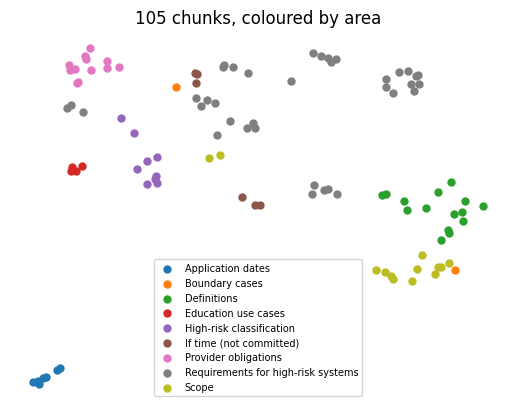

In [74]:
import umap, matplotlib.pyplot as plt
xy = umap.UMAP(n_neighbors=10, random_state=42).fit_transform(vectors)
for area in sorted({c["area"] for c in chunks}):
    pts = xy[[c["area"] == area for c in chunks]]
    plt.scatter(pts[:, 0], pts[:, 1], s=25, label=area)
plt.legend(fontsize=7); plt.title("105 chunks, coloured by area"); plt.axis("off"); plt.show()

**Comment:** Chunks of the same area sit together: the application dates (blue, bottom left), the education use cases (red) and the definitions (green) each form their own group, and the requirements for high-risk systems (grey) form several groups, about one per Article. The dates are far from everything else; this shows why B-06 (grading and a date in one question) does not reach Article 113: one question vector cannot be close to two distant groups.

## What the results show
The Sprint 2 goal was a basic search that returns passages for a few test questions, and it does: hybrid search finds a gold provision for 5 of my 6 questions, and it is the best of the four searches (Recall@5 0.48, MRR 0.64, Precision@5 0.23). It is weaker than we hoped, for three reasons:
1. **The model was not tested in Sprint 1.** bge-base was chosen on paper; on our law and questions it is best only on MRR.
2. **Our questions are hard for one search.** They are long and conversational, some need many provisions (B-05) or two topics (B-06), and the search returns 5 chunks for one question vector.
3. **Six questions are few.** One hit more or less changes a score by up to 0.17.

We do **not** change the settings to fit these six questions, because they are also the questions we check with. Changes are tested in Sprint 3 on the val questions: splitting a question into parts (B-05, B-06), a reranker, and MMR, which avoids near-duplicate chunks.

## Next
- The measurement on all the team's `val` questions (Recall@5, MRR, the instructor's RAG metrics, W&B) is KAN-99; it extends `src/evaluation.ipynb`.